# Data audit

Completeness of the full ERA-40 files, then distributions, outliers, correlations and lag structure of B. Everything after the file checks uses the 30 training winters only (Dec 1957 to Feb 1987), so no decisions rest on test winters. B is the Tyrlis & Hoskins version from `B Value Computation.ipynb`.

In [1]:
import os, sys, glob, calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import skew, kurtosis, zscore
from statsmodels.tsa.stattools import levinson_durbin

sys.path.append("..")
from plot_era40 import _valid_time     # also sets up eccodes in the right order
import eccodes as ec

OUT = "../results/eda"
TRAIN_YEARS = range(1957, 1987)        # winter = December of this year to February of the next

## File completeness

Every monthly file should hold all 7 variables at 4 times a day. Saved to `results/eda/ERA40_file_audit_1957-2002.csv`; loaded if it exists.

In [2]:
AUDIT_FILE = f"{OUT}/ERA40_file_audit_1957-2002.csv"

def audit_file(path):
    ym = path[-6:]
    year, month = int(ym[:4]), int(ym[4:])
    counts, times, bitmaps, lo, hi, nans = {}, set(), 0, np.inf, -np.inf, 0
    with open(path, "rb") as f:
        while (gid := ec.codes_grib_new_from_file(f)) is not None:
            try:
                name = ec.codes_get(gid, "shortName")
                counts[name] = counts.get(name, 0) + 1
                times.add(_valid_time(gid))
                bitmaps += ec.codes_get(gid, "bitmapPresent")
                if name == "pt":
                    v = ec.codes_get_values(gid)
                    lo, hi, nans = min(lo, v.min()), max(hi, v.max()), nans + int(np.isnan(v).sum())
            finally:
                ec.codes_release(gid)
    return dict(month=ym, expected_times=4 * calendar.monthrange(year, month)[1], n_times=len(times), n_variables=len(counts),
                min_count=min(counts.values()), max_count=max(counts.values()), bitmap_messages=bitmaps,
                theta_min=lo, theta_max=hi, theta_nan=nans)

if os.path.exists(AUDIT_FILE):
    file_audit = pd.read_csv(AUDIT_FILE, dtype={"month": str})
else:
    file_audit = pd.DataFrame([audit_file(p) for p in sorted(glob.glob("../data/e4oper.an.pv.*"))])
    file_audit.to_csv(AUDIT_FILE, index=False)

expected_months = pd.period_range("1957-09", "2002-08", freq="M").strftime("%Y%m")
print("files:", len(file_audit), "| months missing:", sorted(set(expected_months) - set(file_audit.month)))
print("files with missing time steps:", (file_audit.n_times != file_audit.expected_times).sum())
print("files with uneven variable counts:", (file_audit.min_count != file_audit.max_count).sum(), "| variables per file:", file_audit.n_variables.unique())
print("messages flagged with missing values:", file_audit.bitmap_messages.sum(), "| NaN theta values:", file_audit.theta_nan.sum())
print(f"theta range over the whole record: {file_audit.theta_min.min():.1f} to {file_audit.theta_max.max():.1f} K")

files: 540 | months missing: []
files with missing time steps: 0
files with uneven variable counts: 0 | variables per file: [7]
messages flagged with missing values: 0 | NaN theta values: 0
theta range over the whole record: 225.0 to 447.8 K


## B: coverage

In [3]:
B = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int)
lons = B.columns.to_numpy()
gaps = pd.date_range(B.index[0], B.index[-1], freq="D").difference(B.index)
print(B.shape, B.index[0].date(), "to", B.index[-1].date(), "| missing days:", len(gaps), "| NaN values:", int(B.isna().sum().sum()))

winters = {y: B.loc[f"{y}-12":f"{y+1}-02"].to_numpy() for y in TRAIN_YEARS}
X = np.concatenate(list(winters.values()))
print("training winters:", len(winters), "| days:", len(X), "| days per winter:", sorted(set(len(w) for w in winters.values())))

(16436, 72) 1957-09-01 to 2002-08-31 | missing days: 0 | NaN values: 0
training winters: 30 | days: 2707 | days per winter: [90, 91]


## Distributions by longitude

      mean    std  skewness  excess_kurtosis  share_B_positive
min -15.27   7.42     -0.64            -0.24              0.07
50%  -9.58   9.93     -0.04             0.16              0.18
max  -2.97  11.66      0.44             1.21              0.36


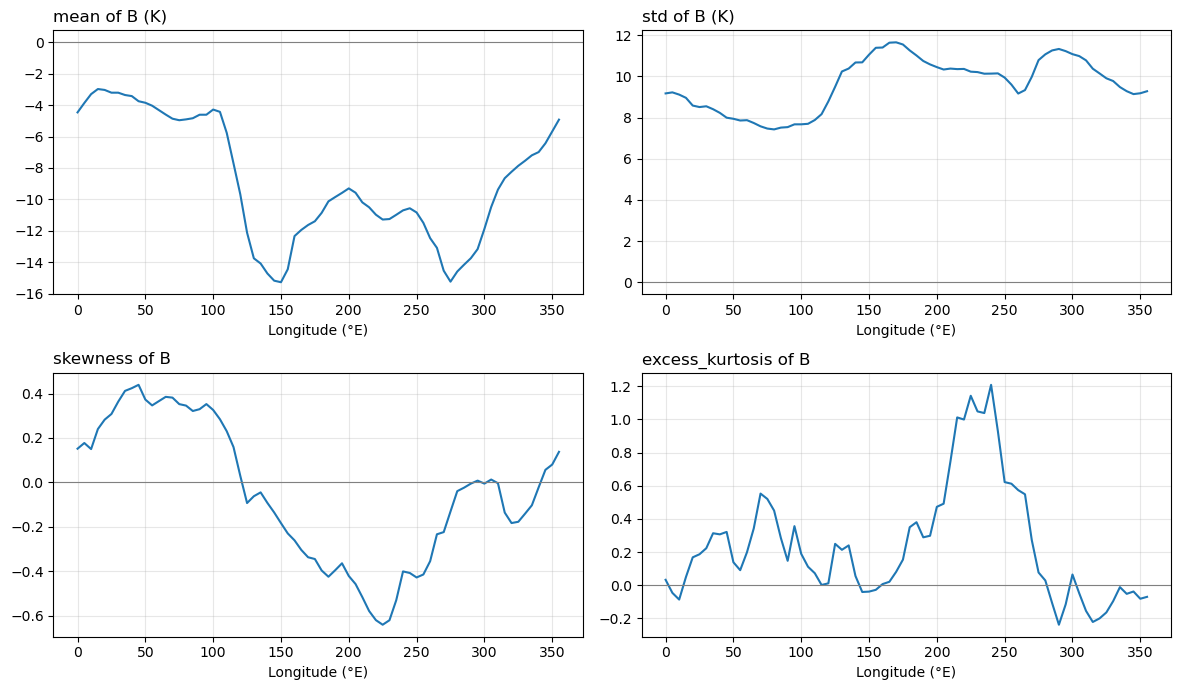

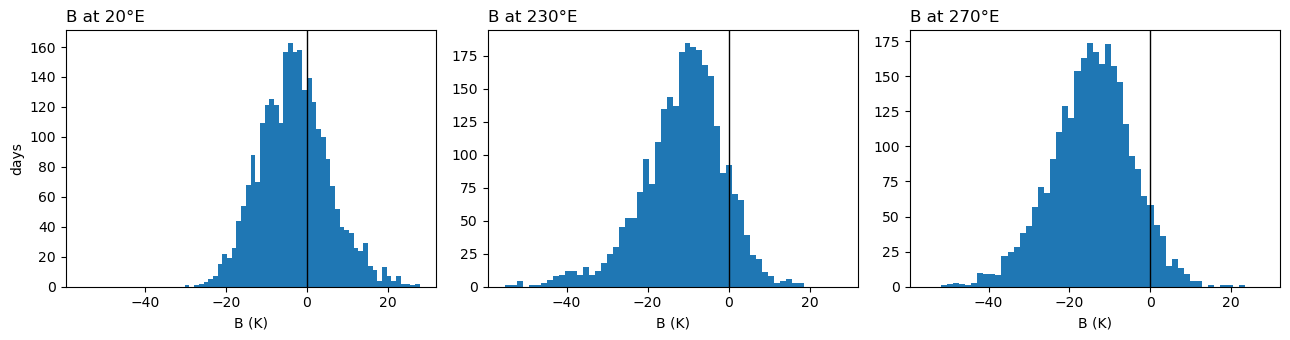

In [4]:
summary = pd.DataFrame({"mean": X.mean(0), "std": X.std(0), "skewness": skew(X, axis=0), "excess_kurtosis": kurtosis(X, axis=0),
                        "share_B_positive": (X > 0).mean(0)}, index=pd.Index(lons, name="lon"))
summary.round(4).to_csv(f"{OUT}/ERA40_B_train_winters_summary_by_longitude.csv")
print(summary.describe().loc[["min", "50%", "max"]].round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, ["mean", "std", "skewness", "excess_kurtosis"]):
    ax.plot(lons, summary[col], color="tab:blue")
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.set_title(f"{col} of B (K)" if col in ("mean", "std") else f"{col} of B", loc="left")
    ax.set_xlabel("Longitude (°E)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/ERA40_B_train_moments_by_longitude.png", dpi=120)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True)
for ax, lon in zip(axes, [20, 230, 270]):
    ax.hist(X[:, lons == lon].ravel(), bins=50, color="tab:blue")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"B at {lon}°E", loc="left")
    ax.set_xlabel("B (K)")
axes[0].set_ylabel("days")
plt.tight_layout()
plt.savefig(f"{OUT}/ERA40_B_train_histograms_20E_230E_270E.png", dpi=120)
plt.show()

## Outliers

Days with B more than 4 standard deviations from its mean at that longitude. These are real extreme flows rather than errors unless they fail the physical range check above, so none are removed.

In [5]:
z = zscore(X, axis=0)
print(f"|z| > 4: {(np.abs(z) > 4).mean():.5f} of values (a normal distribution gives 0.00006); z > 4: {(z > 4).sum()}, z < -4: {(z < -4).sum()}")
print("most extreme values by longitude:", {int(l): int(c) for l, c in zip(lons[np.argsort(-(np.abs(z) > 4).sum(0))[:5]], np.sort((np.abs(z) > 4).sum(0))[::-1][:5])})
print(f"B range: {X.min():.1f} to {X.max():.1f} K")

|z| > 4: 0.00029 of values (a normal distribution gives 0.00006); z > 4: 26, z < -4: 30
most extreme values by longitude: {230: 4, 70: 3, 215: 3, 80: 3, 225: 3}
B range: -65.9 to 36.3 K


## Blocking counts per winter

How rare the targets are, and how much they vary between winters (SBE: SB on that day and the 4 days before it).

LIB: mean over all longitudes 0.192; longitudes with frequency < 1%: 0 of 72; winter-to-winter sd at the peak longitude 0.082 (peak 0.356 at 10°E)
SB: mean over all longitudes 0.273; longitudes with frequency < 1%: 0 of 72; winter-to-winter sd at the peak longitude 0.087 (peak 0.454 at 20°E)
SBE: mean over all longitudes 0.060; longitudes with frequency < 1%: 9 of 72; winter-to-winter sd at the peak longitude 0.084 (peak 0.145 at 25°E)


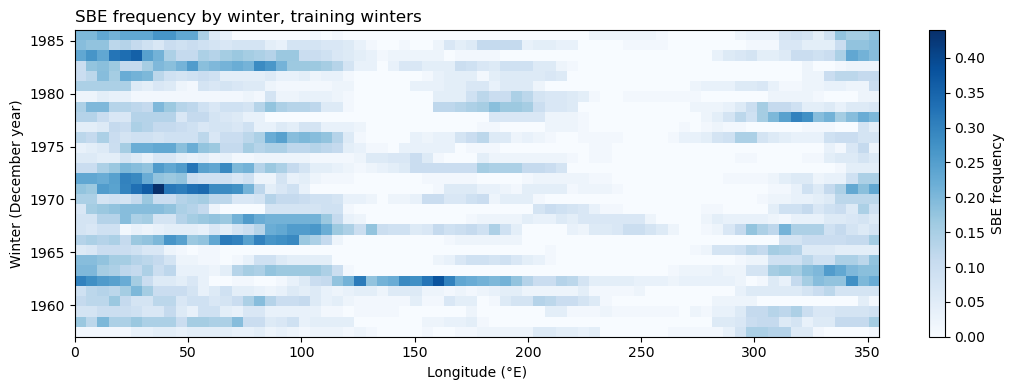

mean B, 1979-86 minus 1957-78: mean over longitudes -0.10 K, range -2.78 to +2.12 K


In [6]:
def flags(b):
    lib = b > 0
    run = lib & np.roll(lib, 1, 1) & np.roll(lib, -1, 1)
    sb = np.zeros_like(lib)
    for k in range(-3, 4):
        sb |= np.roll(run, k, 1)
    fwd = np.zeros(sb.shape, int)
    for t in range(len(sb)):
        fwd[t] = sb[t] * (fwd[t - 1] + 1 if t else 1)
    return lib, sb, fwd >= 5

per_winter = {m: np.array([f[i].mean(0) for f in map(flags, winters.values())]) for i, m in enumerate(["LIB", "SB", "SBE"])}
for m, v in per_winter.items():
    print(f"{m}: mean over all longitudes {v.mean():.3f}; longitudes with frequency < 1%: {(v.mean(0) < 0.01).sum()} of 72; "
          f"winter-to-winter sd at the peak longitude {v[:, v.mean(0).argmax()].std(ddof=1):.3f} (peak {v.mean(0).max():.3f} at {lons[v.mean(0).argmax()]}°E)")

plt.figure(figsize=(11, 4))
plt.imshow(per_winter["SBE"], aspect="auto", origin="lower", cmap="Blues", extent=[lons[0], lons[-1], TRAIN_YEARS[0], TRAIN_YEARS[-1]])
plt.colorbar(label="SBE frequency")
plt.xlabel("Longitude (°E)")
plt.ylabel("Winter (December year)")
plt.title("SBE frequency by winter, training winters", loc="left")
plt.tight_layout()
plt.savefig(f"{OUT}/ERA40_SBE_by_winter_train.png", dpi=120)
plt.show()

# changing observations: first satellite-era winters vs earlier ones
early, late = [np.concatenate([winters[y] for y in ys]).mean(0) for ys in (range(1957, 1979), range(1979, 1987))]
print(f"mean B, 1979-86 minus 1957-78: mean over longitudes {(late - early).mean():+.2f} K, range {(late - early).min():+.2f} to {(late - early).max():+.2f} K")

## Correlations across longitude

mean correlation at separation: {5: 0.9, 10: 0.69, 15: 0.48, 20: 0.3, 25: 0.18, 30: 0.1, 40: 0.04, 60: 0.02}


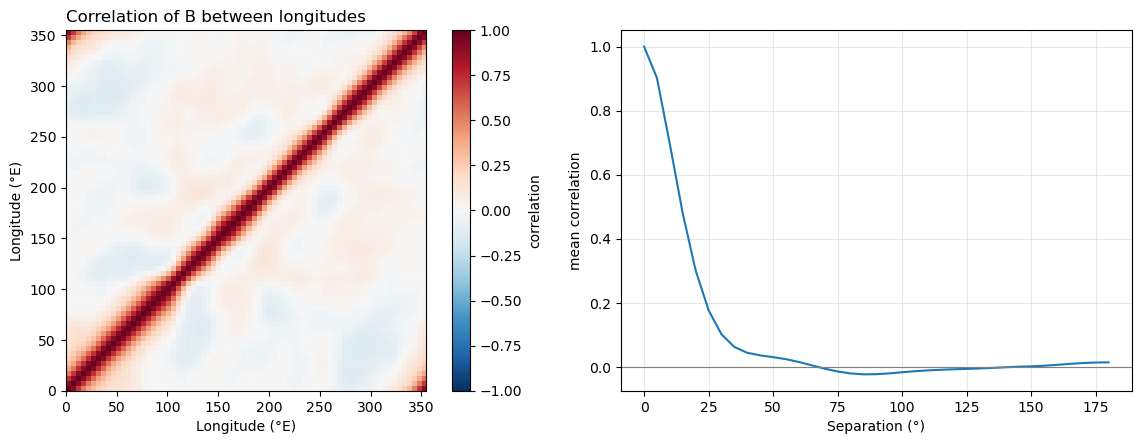

In [7]:
C = np.corrcoef(X.T)
sep = np.array([np.mean(np.diag(np.roll(C, -m, axis=1))) for m in range(37)])
print("mean correlation at separation:", {5 * m: round(float(sep[m]), 2) for m in (1, 2, 3, 4, 5, 6, 8, 12)})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
im = axes[0].imshow(C, origin="lower", cmap="RdBu_r", vmin=-1, vmax=1, extent=[0, 355, 0, 355])
fig.colorbar(im, ax=axes[0], label="correlation")
axes[0].set_xlabel("Longitude (°E)")
axes[0].set_ylabel("Longitude (°E)")
axes[0].set_title("Correlation of B between longitudes", loc="left")
axes[1].plot(5 * np.arange(37), sep, color="tab:blue")
axes[1].axhline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("Separation (°)")
axes[1].set_ylabel("mean correlation")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/ERA40_B_train_correlation_across_longitude.png", dpi=120)
plt.show()

## Lag structure

Autocorrelation and partial autocorrelation of B at lags 1-20 days, using only pairs within a winter. Partial autocorrelation comes from the autocorrelation by Levinson-Durbin.

mean ACF, lags 1, 2, 3, 5, 10, 20: [0.643 0.376 0.284 0.183 0.067 0.027]
mean PACF, lags 1, 2, 3, 4, 5: [ 0.643 -0.063  0.115  0.016  0.031]
lag 1 across longitudes: 0.594 to 0.725, highest at 135°E


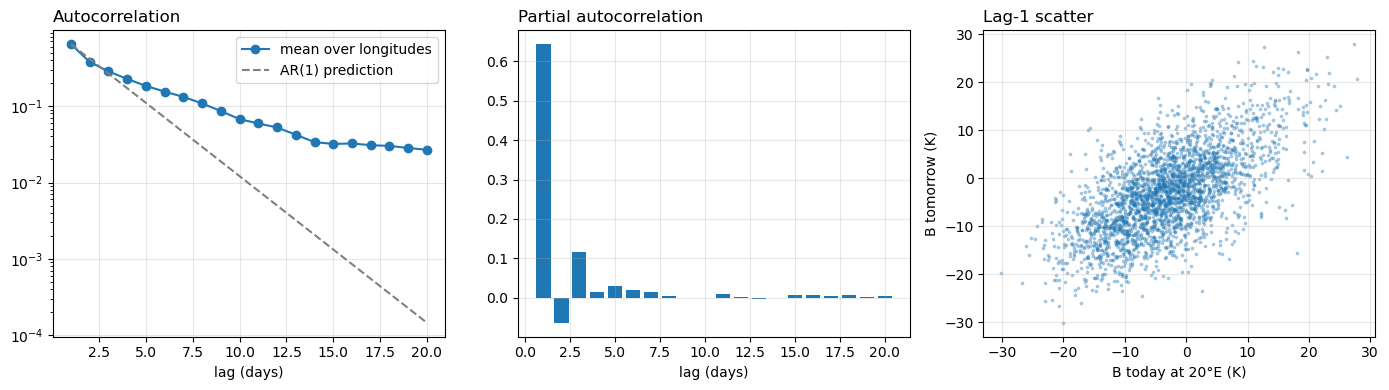

In [8]:
centred = {y: w - X.mean(0) for y, w in winters.items()}
den = sum((c ** 2).sum(0) for c in centred.values())
acf = np.array([sum((c[:-k] * c[k:]).sum(0) for c in centred.values()) / den for k in range(1, 21)])   # (lags, longitudes)

def pacf_from_acf(rho):
    return levinson_durbin(np.r_[1.0, rho], nlags=len(rho), isacov=True)[2][1:]

mean_acf = acf.mean(1)
mean_pacf = pacf_from_acf(mean_acf)
print("mean ACF, lags 1, 2, 3, 5, 10, 20:", np.round(mean_acf[[0, 1, 2, 4, 9, 19]], 3))
print("mean PACF, lags 1, 2, 3, 4, 5:", np.round(mean_pacf[:5], 3))
print(f"lag 1 across longitudes: {acf[0].min():.3f} to {acf[0].max():.3f}, highest at {lons[acf[0].argmax()]}°E")
pd.DataFrame({"lag": range(1, 21), "acf": mean_acf, "pacf": mean_pacf}).round(4).to_csv(f"{OUT}/ERA40_B_train_mean_acf_pacf.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(range(1, 21), mean_acf, "o-", label="mean over longitudes")
axes[0].plot(range(1, 21), mean_acf[0] ** np.arange(1, 21), "--", color="gray", label="AR(1) prediction")
axes[0].set_yscale("log")
axes[0].set_xlabel("lag (days)")
axes[0].set_title("Autocorrelation", loc="left")
axes[0].legend()
axes[1].bar(range(1, 21), mean_pacf, color="tab:blue")
axes[1].set_xlabel("lag (days)")
axes[1].set_title("Partial autocorrelation", loc="left")
j = list(lons).index(20)
x0, x1 = np.concatenate([w[:-1, j] for w in winters.values()]), np.concatenate([w[1:, j] for w in winters.values()])
axes[2].scatter(x0, x1, s=3, alpha=0.3)
axes[2].set_xlabel("B today at 20°E (K)")
axes[2].set_ylabel("B tomorrow (K)")
axes[2].set_title("Lag-1 scatter", loc="left")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT}/ERA40_B_train_lag_structure.png", dpi=120)
plt.show()